## Table of Contents
A1. [Question for Analysis](#A1.-Question-for-Analysis)

A2. [Benefit from Analysis](#A2.-Benefit-from-Analysis)

A3. [Data Identification](#A3.-Data-Identification)

B1. [Code](#B1.-Code)

B2. [Output](#B2.-Output)

B3. [Justification](#B3.-Justification)

C1. [Univariate Statistics and Visual of Findings](#C.-Univariate-Statistics-and-Visual-of-Findings)

D1. [Bivariate Statistics and Visual of Findings](#D.-Bivariate-Statistics-and-Visual-of-Findings)

E1. [Results of Analysis](#E1.-Results-of-Analysis)

E2. [Limitations of Analysis](#E2.-Limitations-of-Analysis)

E3. [Recommended Course of Action](#E3.-Recommended-Course-of-Action)


G. [Sources-for-Third-Party-Code](#G.-Sources-for-Third-Party-Code)

H. [Sources](#H.-Sources)


### A1. Question for Analysis

The analysis question for this assessment is, "Is there a difference in weekly outage time between customers who have churned, and those who have not?" The null hypothesis for this question states that there is no difference between the mean weekly outage time between the churned and non-churned populations. If the null hypothesis is disproven, then we will adopt the alternative hypothesis: that there is a statistically measurable difference in the mean weekly outage time between the population of customers who have churned, and the population of customers who have not churned.

The null and alternative hypotheses for this question can be written as follows:

H<sub>0</sub> = The population mean for Outage_sec_perweek for churned participants is not different than that of participants who have not churned.

H<sub>a</sub> = The population mean for Outage_sec_perweek for churned participants is different than that of participants who have not churned.

### A2. Benefit from Analysis

Determining whether or not there is a difference in service outage time in households that have churned (that is, discontinued service within the past month) can help stakeholders drive decisions around preventing churn; for example, if the analysis finds that customers who churned had longer periods of service outages, then steps could be taken to prevent churn by reducing service outages. Alternatively, if the null hypothesis is rejected, the ISP could instead decide to look at addressing other issues that could potentially be contributing to churn, thus saving the time and effort that would have been spent attempting to reduce service outage time.

### A3. Data Identification

In order to answer the research question posed above, we will need to incorporate the "Outage_sec_perweek" and "Churn" variables into the analysis. Outage_sec_perweek is a continuous numeric variable that stores the average service outage time per week for the given household, in seconds; the "Churn" variable is a boolean (Yes/No) categorical variable that indicates whether or not a customer has churned.

### B1. Code

In [1]:
# Import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Read the churn dataset

churnfile = pd.read_csv('../data/churn_clean.csv', keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

In [3]:
# Inspect dataset; ensure no missing values
print(churnfile.info())
print(churnfile.head())
print(churnfile.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CaseOrder             10000 non-null  int64  
 1   Customer_id           10000 non-null  object 
 2   Interaction           10000 non-null  object 
 3   UID                   10000 non-null  object 
 4   City                  10000 non-null  object 
 5   State                 10000 non-null  object 
 6   County                10000 non-null  object 
 7   Zip                   10000 non-null  int64  
 8   Lat                   10000 non-null  float64
 9   Lng                   10000 non-null  float64
 10  Population            10000 non-null  int64  
 11  Area                  10000 non-null  object 
 12  TimeZone              10000 non-null  object 
 13  Job                   10000 non-null  object 
 14  Children              10000 non-null  int64  
 15  Age                 

In [4]:
# Split the population into churned and not-churned households
# Grab only Outage_sec_perweek column
# Print info of each new dataset to determine record counts

churn_yes = churnfile[churnfile['Churn'] == 'Yes']['Outage_sec_perweek']
churn_no = churnfile[churnfile['Churn'] == 'No']['Outage_sec_perweek']

print(churn_yes)
print(churn_no)
print("\n")
print("Distribution of Outage Time for Churned Population:")
print(churn_yes.describe())
print("\n")
print("Distribution of Outage Time for Unchurned Population:")
print(churn_no.describe())
print("\n")

1       11.699080
4        8.147417
6       11.182725
7        7.791632
14      11.790730
          ...    
9932    15.713720
9935    16.865360
9938     9.741873
9939    10.818520
9979    12.098460
Name: Outage_sec_perweek, Length: 2650, dtype: float64
0        7.978323
2       10.752800
3       14.913540
5        8.420993
8        5.739006
          ...    
9995     9.415935
9996     6.740547
9997     6.590911
9998    12.071910
9999    11.754720
Name: Outage_sec_perweek, Length: 7350, dtype: float64


Distribution of Outage Time for Churned Population:
count    2650.000000
mean       10.001073
std         2.970408
min         0.232279
25%         8.017041
50%         9.961190
75%        11.949793
max        21.207230
Name: Outage_sec_perweek, dtype: float64


Distribution of Outage Time for Unchurned Population:
count    7350.000000
mean       10.002128
std         2.978242
min         0.099747
25%         8.018866
50%        10.035830
75%        11.981074
max        20.625040
Name: O

(array([  6.,   8.,  23.,  37.,  82., 161., 219., 302., 377., 380., 343.,
        264., 192., 117.,  80.,  29.,  19.,   6.,   4.,   1.]),
 array([ 0.2322795 ,  1.28102702,  2.32977455,  3.37852208,  4.4272696 ,
         5.47601712,  6.52476465,  7.57351218,  8.6222597 ,  9.67100723,
        10.71975475, 11.76850228, 12.8172498 , 13.86599733, 14.91474485,
        15.96349238, 17.0122399 , 18.06098743, 19.10973495, 20.15848247,
        21.20723   ]),
 <BarContainer object of 20 artists>)

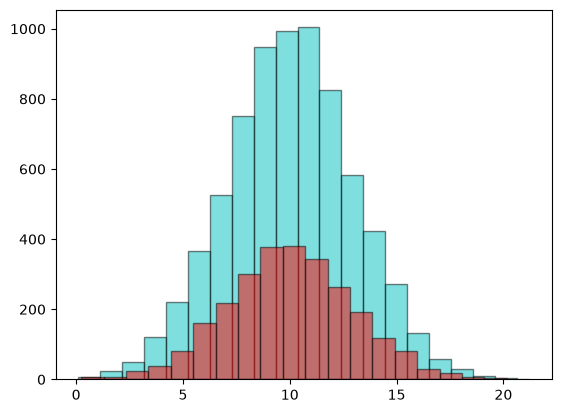

In [5]:
# Verify that both populations are normally distributed

plt.hist(churn_no, bins=20, color='c', edgecolor='k', alpha=0.5)
plt.hist(churn_yes, bins=20, color='r', edgecolor='k', alpha=0.5)

In [6]:
# Verify both groups have a similar variance
print(np.var(churn_no), np.var(churn_yes))

8.86871627404491 8.819991927118513


In [7]:
# Both groups appear to be normally distributed and have similar variances;
# this means that a two-sample t-test would be appropriate for determining whether
# there is a statistically significant difference in the means between these two
# populations

# Perform a two-sample t-test using the new churn_yes and churn_no datasets

t_result = stats.ttest_ind(churn_no, churn_yes)
print(t_result)

TtestResult(statistic=np.float64(0.015639241921385327), pvalue=np.float64(0.98752251103374), df=np.float64(9998.0))


### B2. Output

The results from the analysis are as follows:

In [8]:
print(t_result)

TtestResult(statistic=np.float64(0.015639241921385327), pvalue=np.float64(0.98752251103374), df=np.float64(9998.0))


The p-value for this test is notably high at 0.9875. This is significantly larger than the alpha value of 0.05; therefore we cannot reject the null hypothesis that the population mean between the two datasets is equal.

Additionally, the sample variances of these two datasets were calculated to ensure that a two-sample t-test was an appropriate method to compare the data. The averages and standard deviations of these populations were also calculated for comparison. The results of these comparisons are below:

In [9]:
print("Variances of Unchurned Population and Churned Population:")
print(np.var(churn_no), np.var(churn_yes))
print("\n")
print("Distribution of Outage Time for Churned Population:")
print(churn_yes.describe())
print("\n")
print("Distribution of Outage Time for Unchurned Population:")
print(churn_no.describe())
print("\n")

Variances of Unchurned Population and Churned Population:
8.86871627404491 8.819991927118513


Distribution of Outage Time for Churned Population:
count    2650.000000
mean       10.001073
std         2.970408
min         0.232279
25%         8.017041
50%         9.961190
75%        11.949793
max        21.207230
Name: Outage_sec_perweek, dtype: float64


Distribution of Outage Time for Unchurned Population:
count    7350.000000
mean       10.002128
std         2.978242
min         0.099747
25%         8.018866
50%        10.035830
75%        11.981074
max        20.625040
Name: Outage_sec_perweek, dtype: float64




### B3. Justification

A two-sample t-test can be used to determine whether the population mean between two groups is equivalent. (GeeksForGeeks, 2022) This is an appropriate method for determining whether there is any difference in Outage_sec_perweek between the populations that have churned, and have not churned. A difference in population mean for Outage_sec_perweek between these two samples would indicate that, on average, there is a statistically significant difference in service outage time between customers in these two groups. Understanding whether or not such a difference exists would help the business in taking steps to prevent customer churn. 

There are a number of factors to take into consideration when performing a two-sample t-test; one, the sample groups must be indepdendent; two, the sample groups must have normal distributions; and three, the sample groups must have similar variances. (GeeksForGeeks, 2022) We can assume independence, as the outage time of churned customers would not affect non-churned customers, and vice-versa. Additionally, as we can see below in the histograms, both the churn_no and churn_yes groups are normally distributed:

(array([  6.,   8.,  23.,  37.,  82., 161., 219., 302., 377., 380., 343.,
        264., 192., 117.,  80.,  29.,  19.,   6.,   4.,   1.]),
 array([ 0.2322795 ,  1.28102702,  2.32977455,  3.37852208,  4.4272696 ,
         5.47601712,  6.52476465,  7.57351218,  8.6222597 ,  9.67100723,
        10.71975475, 11.76850228, 12.8172498 , 13.86599733, 14.91474485,
        15.96349238, 17.0122399 , 18.06098743, 19.10973495, 20.15848247,
        21.20723   ]),
 <BarContainer object of 20 artists>)

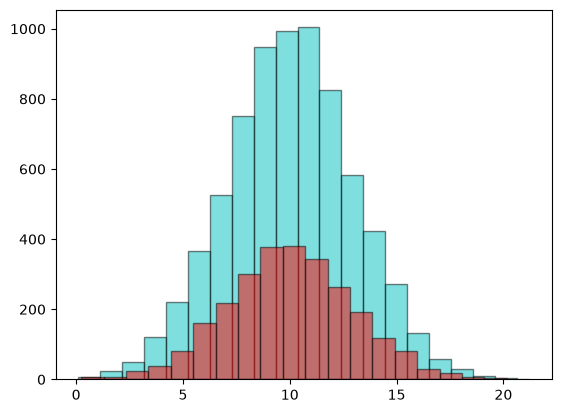

In [10]:
plt.hist(churn_no, bins=20, color='c', edgecolor='k', alpha=0.5)
plt.hist(churn_yes, bins=20, color='r', edgecolor='k', alpha=0.5)

The variances for these groups is also similar:

In [11]:
print(np.var(churn_no), np.var(churn_yes))

8.86871627404491 8.819991927118513


As the distributions for both groups appears to be normal, their variances are similar, and the two samples can be assumed to be independent, the two-sample t-test is an appropriate methodology for determining if there is a statistically significant difference in the population means between the churned group, and the group that has not churned.

### C1. Univariate Statistics and Visual of Findings

Below I've included statistics and visualizations detailing the distributions of two continuous variables, "Income" and "Outage_sec_perweek", as well as two categorical variables, "Gender" and "Marital."

"Income" represents the household income for each customer. The distribution for Income is skewed right, with a majority of values on the left side of the distribution, and a mean value (39806.93) that is higher than the median (33170.61). The highest reported value in this population is 258900.70, and the lowest is 348.67.

"Outage_sec_perweek" represents the average amount of time, measured in seconds, a customer experiences a service outage each week. This variable is normally distributed. The mean and median are relatively close (10 and 10.02, respectively). The values range from 2.97 to 21.2.

"Gender" only has three valid values: male, female, and nonbinary. Female had the highest occurance rate, with 5025 female respondents out of a total of 10000 records. There were 4744 male respondents, and 231 nonbinary respondents.

"Marital" respresents the marital status of the accountholders in each customer household. Valid values for this field include divorced, widowed, separated, never married, and married. The majority of respondents are not married; 2092 are divorced, 2027 are widowed, 2014 are separated, and 1956 have never been married. Only 1911 respondents indicated that they are married, representing around just 19% of the total surveyed population.

count     10000.000000
mean      39806.926771
std       28199.916702
min         348.670000
25%       19224.717500
50%       33170.605000
75%       53246.170000
max      258900.700000
Name: Income, dtype: float64


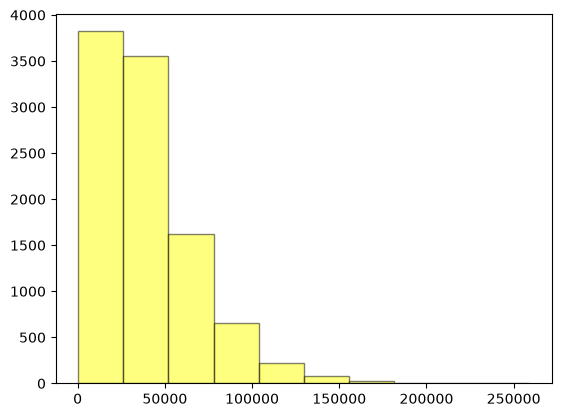

In [12]:
# Univariate statistics for continuous variables
# First continuous variable: Income
churn_inc = churnfile["Income"]
plt.hist(churn_inc, color="yellow", edgecolor="k", alpha=0.5)
print(churn_inc.describe())

count    10000.000000
mean        10.001848
std          2.976019
min          0.099747
25%          8.018214
50%         10.018560
75%         11.969485
max         21.207230
Name: Outage_sec_perweek, dtype: float64


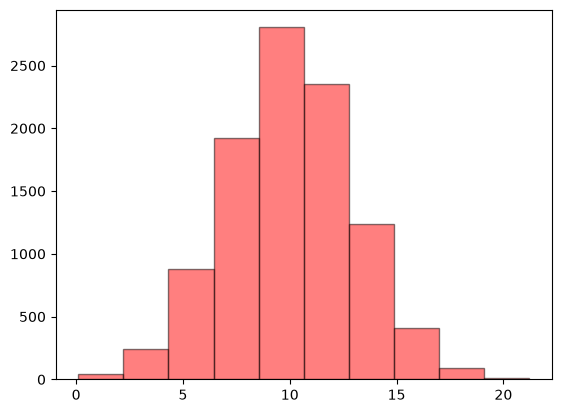

In [13]:
# Second continous variable: Outage time per week
churn_outage = churnfile["Outage_sec_perweek"]
plt.hist(churn_outage, color="red", edgecolor="k", alpha=0.5)
print(churn_outage.describe())

count      10000
unique         3
top       Female
freq        5025
Name: Gender, dtype: object
Gender
Female       5025
Male         4744
Nonbinary     231
Name: count, dtype: int64


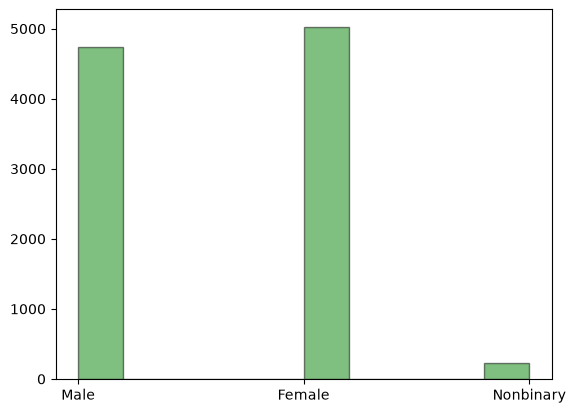

In [14]:
# Univariate statistics for categorical variables
# First categorical variable: Gender
churn_gender = churnfile['Gender']
plt.hist(churn_gender, color='green', edgecolor='k', alpha=0.5)
print(churn_gender.describe())
print(churn_gender.value_counts())

count        10000
unique           5
top       Divorced
freq          2092
Name: Marital, dtype: object
Marital
Divorced         2092
Widowed          2027
Separated        2014
Never Married    1956
Married          1911
Name: count, dtype: int64


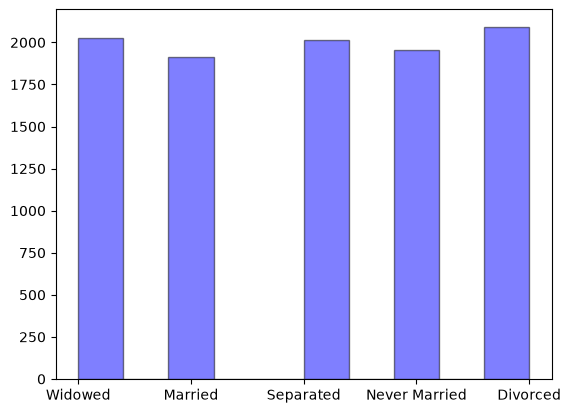

In [15]:
# Second categorical variable: Marital
churn_marital = churnfile['Marital']
plt.hist(churn_marital, color='blue', edgecolor='k', alpha=0.5)
print(churn_marital.describe())
print(churn_marital.value_counts())

### D1. Bivariate Statistics and Visual of Findings

Below I've included bivarate statistical analysis of two pairings of variables. The first analysis shows a comparison between the continuous variable types Tenure, which is the number of months a customer has been actively subscribed to the ISP's service, and Income, which is the household income of the customer. The scatterplot below shows the relationship between these two variables. Overall there seems to be little relationship between these two variables, as indicated by the extremely low correlation coefficient of 0.002114. As shown in the scatterplot, in cases of both high and low tenure lengths the income levels of all households surveyed seem to fall below the 100,000 mark. Clustering in the data becomes increasingly sparse as the income increases; this appears to occur regardless of customer tenure. There is a small gap in the center of the scatterplot, which indicates a lower number of respondants with tenures within the 25- to 35-month range.

The second analysis compares two categorical variables, Techie and Churn. Techie is a self-reported indicator reflecting a respondent's technical knowledge; a "yes" in this field reflects a respondent who feels they are technically-minded, while a "no" indicates the opposite. As previously discussed, the Churn variable indicates whether a customer has cancelled their service with the ISP. 7350 respondents have not churned, while 2650 have churned. 1679 respondents indicated that they are techies and 8321 indicated that they are not techies. Of the non-techie population, 25.17% have churned and 74.82% have not; of the techies, 33.05% have churned and 66.94% have not. Looking at it another way, out of the total churned population, 20.94% are techies, whereas in the total not-churned population, 15.29% are techies. These findings may indicate that techies are slightly overrepresented in the churned population. The accompanying stacked bar chart breaks the total population down into churned and not-churned groups, and indicates the proportion of each group are techies.

Distribution of Income:
count     10000.000000
mean      39806.926771
std       28199.916702
min         348.670000
25%       19224.717500
50%       33170.605000
75%       53246.170000
max      258900.700000
Name: Income, dtype: float64


Distribution of Tenure:
count    10000.000000
mean        34.526188
std         26.443063
min          1.000259
25%          7.917694
50%         35.430507
75%         61.479795
max         71.999280
Name: Tenure, dtype: float64


Correlation of Income and Tenure:
          Income    Tenure
Income  1.000000  0.002114
Tenure  0.002114  1.000000


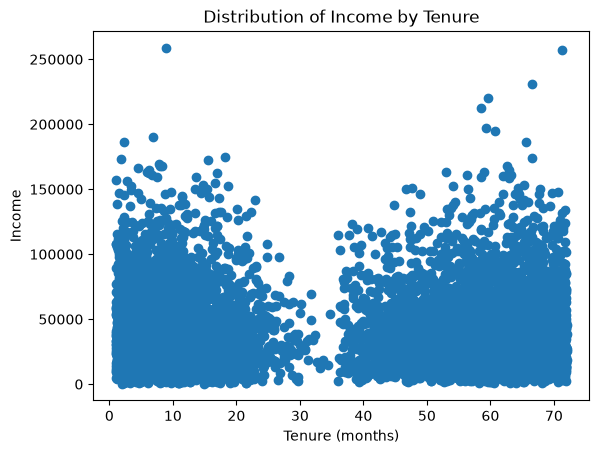

In [16]:
# Bivariate Statistics - Continuous
# Distribution of Income vs Tenure
# Print descriptive statistics for each, along with correlation between them
# Then generate scatterplot to visualize the relationship

print("Distribution of Income:")
print(churnfile['Income'].describe())
print("\n")
print("Distribution of Tenure:")
print(churnfile['Tenure'].describe())
print("\n")
print("Correlation of Income and Tenure:")
print(churnfile[['Income','Tenure']].corr())

plt.title("Distribution of Income by Tenure")
plt.xlabel('Tenure (months)')
plt.ylabel('Income')
plt.scatter(churnfile['Tenure'], churnfile['Income'])
plt.show()


In [17]:
# Bivariate Statistics - Categorical
# Distributions of Techie and Churn
# Crosstab of Techie and Churn to get counts for bar graph
# Print crosstab to show value counts for dataset
# Print percentages - first perc of techies that churned, then perc of churned pop that are techies

churn_techchurn = churnfile[['Techie','Churn']]

crosschurn = pd.crosstab(index = churn_techchurn.Churn, columns = churn_techchurn.Techie)
crosschurn_perc = pd.crosstab(index = churn_techchurn.Techie, columns = churn_techchurn.Churn, normalize='index')
crosschurn_perc2 = pd.crosstab(index = churn_techchurn.Churn, columns = churn_techchurn.Techie, normalize='index')


print("Crosstab of Techie and Churn:")
print(crosschurn)
print("\n")
print("Percentage of Techie and Non-Techie Populations that have Churned:")
print(crosschurn_perc)
print("\n")
print("Percentage of Churned Population by Techie Response:")
print(crosschurn_perc2)

Crosstab of Techie and Churn:
Techie    No   Yes
Churn             
No      6226  1124
Yes     2095   555


Percentage of Techie and Non-Techie Populations that have Churned:
Churn         No       Yes
Techie                    
No      0.748227  0.251773
Yes     0.669446  0.330554


Percentage of Churned Population by Techie Response:
Techie        No       Yes
Churn                     
No      0.847075  0.152925
Yes     0.790566  0.209434


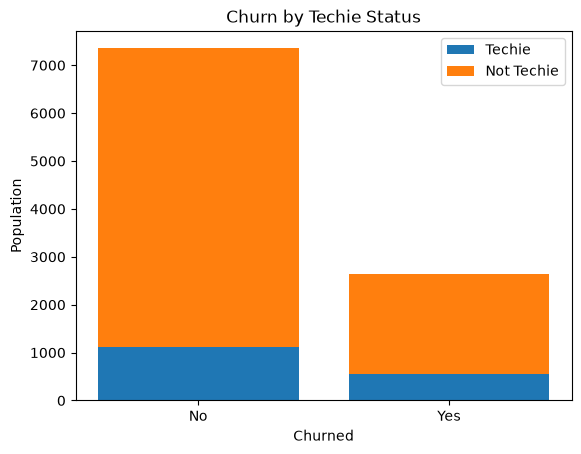

In [18]:
#Create a stacked bar chart to show relation between Churn and Techie
fig, ax = plt.subplots()
ax.bar(crosschurn.columns, crosschurn['Yes'], label='Techie')
ax.bar(crosschurn.columns, crosschurn['No'], bottom=crosschurn['Yes'],
       label='Not Techie')
ax.set_title('Churn by Techie Status')
ax.set_xlabel('Churned')
ax.set_ylabel('Population')
ax.legend()

### E1. Results of Analysis

The hypothesis test performed above utilized a two-sample t-test to determine whether there was any difference between the population means in customer service outage time between customers who had and had not churned. The null hypothesis stated that there was no difference between these populations; the alternative hypothesis stated that there was a difference. The two-sample t-test returned a p-value of 0.9875, which is well above the alpha value of 0.05. Therefore, the null hypothesis could not be rejected; there does not appear to be any statistically significant difference in the sample means of these two populations.

### E2. Limitations of Analysis

As with all analyses, there are limitations that must be taken into account. The analysis itself is a mathematically-formed "best guess" as to the equivalence between the churned and not-churned populations. The p-value of 0.9875 indicates that we can say with 98.75% certainty that the population means are equivalent; this does mean that there is still an extremely slight chance that the null hypothesis is factually inaccurate and should have been rejected. The analysis is also reliant entirely on the quality of the data being used; if there were issues in collecting the data for this survey, the results of the analysis would likewise be inaccurate and should be discarded.

### E3. Recommended Course of Action

Based on the results of this test, I would recommend that the ISP not consider service reliability when determing how to reduce customer churn. There seems to be no difference between the outage times for customers who did churn and those who did not, which implies that service outage time was not a contributing factor in these customers deciding to cancel their service. I would instead recommend that further analyses be performed, focusing on other variables within this dataset, to try to determine if there is any other contributing factor to customer churn.

### G. Sources for Third-Party Code

Matplotlib Documentation. (2024) *matplotlib.pyplot.boxplot* https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html

Python Charts. (2021) *Stacked Bar Charts with Labels in Matplotlib* https://www.pythoncharts.com/matplotlib/stacked-bar-charts-labels/

Pandas Documentation. (2024) *pandas.crosstab* https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.crosstab.html

Pandas Documentation. (2024) *pandas.DataFrame.corr* https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html

Python for Data Science. (2024) *Independent T-test* https://www.pythonfordatascience.org/independent-samples-t-test-python/

SciPy Documentation. (2024) *scipy.stats.
ttest_ind* https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

Stackabuse. *Matplotlib Box Plot Tutorial and Examples.* (2023, February 24) https://stackabuse.com/matplotlib-box-plot-tutorial-and-examples/

### H. Sources

GeeksForGeeks. (2022, October 17) *How to Conduct a Two Sample T-Test in Python* https://www.geeksforgeeks.org/how-to-conduct-a-two-sample-t-test-in-python/